# simlake showcase

A tour of the simlake prototype: a versioned [Zarr v3](https://zarr.dev) /
[Icechunk](https://icechunk.io) lake for MD trajectories that MDAnalysis and xarray
can both read.

The data is adenylate kinase (AdK) in water from MDAnalysisTests: 47,681 atoms, of
which 3,341 are protein, over 10 frames. Everything runs in a temporary directory.
The last section uses a local [moto](https://github.com/getmoto/moto) server in place of S3.

This file is the source; `showcase.ipynb` is generated from it, with outputs:

```bash
micromamba run -n simlake jupytext --to notebook --execute examples/showcase.py
```

In [1]:
import warnings

warnings.filterwarnings("ignore")

import logging
import os
import shutil
import socket
import tempfile
import time

import dask
import matplotlib.pyplot as plt
import numpy as np
import MDAnalysis as mda
from MDAnalysis import transformations
from MDAnalysis.analysis import rms
from MDAnalysisTests.datafiles import TPR, XTC

import simlake as sl

logging.getLogger("werkzeug").setLevel(logging.ERROR)

try:
    from IPython.display import display
except ImportError:  # running as a plain script
    display = print

# Chart style: categorical slots 1-2 of the reference palette (validated for CVD and
# contrast on this surface), thin marks, recessive grid, text in ink, not series colours.
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
REPLICA_COLOR = {0: BLUE, 1: ORANGE}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "lines.markersize": 6, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110, "axes.axisbelow": True,
})


def mb(n):
    return f"{n / 2**20:.1f} MB"


workdir = tempfile.mkdtemp(prefix="simlake-showcase-")
raw = os.path.join(workdir, "raw")
os.makedirs(raw)
xtc_path = shutil.copy(XTC, os.path.join(raw, "adk_water_run0.xtc"))

## 1. Build a lake from the files you already have

A **system** is one topology. Its **replicas** are trajectories of that topology.
There are two ways to add one:

* **register** an existing file in place. Its frames become references, and no
  coordinates are copied.
* **copy it in** natively: quantized to XTC precision, compressed with pcodec, with
  each atom group (here protein, water, ions) in its own chunks.

The test XTC has the protein split across the periodic boundary. Copying in goes
through MDAnalysis, so a transformation makes the protein whole on the way in. The
registered replica keeps the raw file as it is.

In [2]:
lake = sl.Lake.create(os.path.join(workdir, "adk.lake"))
lake.create_system("adk_water", TPR, metadata={"forcefield": "oplsaa", "engine": "gromacs"})

t0 = time.perf_counter()
lake.register("adk_water", xtc_path, metadata={"temperature": 300, "run": "run0"})
t_register = time.perf_counter() - t0

run1 = mda.Universe(TPR, XTC)
run1.trajectory.add_transformations(transformations.unwrap(run1.select_atoms("protein")))
t0 = time.perf_counter()
lake.add_replica("adk_water", run1, metadata={"temperature": 310, "run": "run1", "unwrapped": True})
t_copy = time.perf_counter() - t0

virtual = lake.system("adk_water").replica_group(0)
native = lake.system("adk_water").replica_group(1)
copied_in = sum(a.nbytes_stored() for name, a in virtual.arrays() if name != "position")
by_group = lake.system("adk_water").stored_bytes(1)
total = sum(by_group.values())

print(f"replica 0  registered in place  {t_register:5.2f} s   copied: {copied_in:,d} B "
      f"(time/step/box only); the {mb(os.path.getsize(xtc_path))} XTC stays put")
print(f"replica 1  copied in, whole     {t_copy:5.2f} s   stored: {mb(total)} (XTC: {mb(os.path.getsize(XTC))})")
print("           by group:", ", ".join(f"{k} {mb(v)} ({100 * v / total:.0f}%)" for k, v in by_group.items()))

replica 0  registered in place   0.01 s   copied: 2,400 B (time/step/box only); the 1.6 MB XTC stays put
replica 1  copied in, whole      0.96 s   stored: 1.7 MB (XTC: 1.6 MB)
           by group: protein 0.1 MB (6%), water 1.6 MB (94%), ions 0.0 MB (0%)


## 2. Find data with SQL

The catalog has one row per replica, with system and replica metadata flattened in.
DuckDB queries it.

In [3]:
display(lake.query("""
    SELECT system, replica, storage, n_frames, total_time_ns, temperature, "system.forcefield"
    FROM trajectories ORDER BY replica
"""))

,system,replica,storage,n_frames,total_time_ns,temperature,system.forcefield
0,adk_water,0,virtual:xtc,10,0.9,300,oplsaa
1,adk_water,1,native,10,0.9,310,oplsaa


## 3. MDAnalysis: a replica is just a Universe

`lake.universe(...)`, or `mda.Universe("simlake://...")`, returns a normal Universe.
Topology (charges, masses, bonds) and coordinates both come from the lake, so
selections, transformations and analysis classes work unchanged.

`groups="protein"` builds a protein-only Universe that reads only the protein's chunks.

backbone RMSD of replica 0 (A), unwrapped on the fly: [0.   1.13 1.67 1.98 1.95 1.61 1.61 1.83 1.86 1.64]


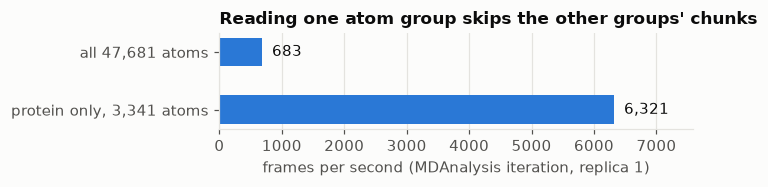

In [4]:
u = lake.universe("adk_water", 0)
u.trajectory.add_transformations(transformations.unwrap(u.select_atoms("protein")))
mda_rmsd = rms.RMSD(u, select="backbone").run().results.rmsd[:, 2]
print("backbone RMSD of replica 0 (A), unwrapped on the fly:", np.round(mda_rmsd, 2))

speeds = {}
for label, kw in (("all 47,681 atoms", {}), ("protein only, 3,341 atoms", {"groups": "protein"})):
    uu = lake.universe("adk_water", 1, **kw)
    t0 = time.perf_counter()
    for _ in range(5):
        uu.trajectory.close()  # drop the decoded block, so every pass really decodes
        for _ in uu.trajectory:
            uu.atoms.positions
    speeds[label] = 5 * uu.trajectory.n_frames / (time.perf_counter() - t0)

fig, ax = plt.subplots(figsize=(6.5, 1.8))
labels = list(speeds)
ax.barh(labels, [speeds[k] for k in labels], color=BLUE, height=0.5)
for i, k in enumerate(labels):
    ax.text(speeds[k], i, f"  {speeds[k]:,.0f}", va="center", color=INK)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("frames per second (MDAnalysis iteration, replica 1)")
ax.set_title("Reading one atom group skips the other groups' chunks")
ax.set_xlim(0, max(speeds.values()) * 1.2)
plt.tight_layout()
plt.show()

## 4. xarray + dask: every replica at once, lazily, on all cores

`lake.open_dataset()` puts every replica of a system in one xarray Dataset of dask
arrays: `(replica, frame, atom, spatial)`, chunked on atom-group boundaries. The
`.md` accessor adds MDAnalysis selections (`ds.md.select("name CA")`) and an RMSD that
runs MDAnalysis' QCP kernel inside dask. No MDAnalysis parallel backend is involved.

The workflow follows Pangeo: **build** the analyses as task graphs (nothing is read),
**compute** them together (chunk reads are shared, threads do the work), and get
**labelled** results back.

In [5]:
ds = lake.open_dataset("adk_water")
ds

<xarray.Dataset> Size: 15MB
Dimensions:       (replica: 2, frame: 10, box_vector: 3, spatial: 3, atom: 47681)
Coordinates:
  * replica       (replica) int64 16B 0 1
  * frame         (frame) int64 80B 0 1 2 3 4 5 6 7 8 9
  * spatial       (spatial) <U1 12B 'x' 'y' 'z'
  * atom          (atom) int64 381kB 0 1 2 3 4 ... 47676 47677 47678 47679 47680
    atom_group    (atom) <U7 1MB 'protein' 'protein' 'protein' ... 'ions' 'ions'
    atom_name     (atom) <U4 763kB 'N' 'H1' 'H2' 'H3' ... 'NA' 'NA' 'NA' 'NA'
    atom_resname  (atom) <U4 763kB 'MET' 'MET' 'MET' 'MET' ... 'NA+' 'NA+' 'NA+'
    atom_resid    (atom) int64 381kB 1 1 1 1 1 ... 11298 11299 11300 11301 11302
Dimensions without coordinates: box_vector
Data variables:
    time          (replica, frame) float64 160B 0.0 100.0 200.0 ... 800.0 900.0
    step          (replica, frame) int64 160B 0 50000 100000 ... 400000 450000
    box           (replica, frame, box_vector, spatial) float32 720B dask.array<chunksize=(1, 10, 3, 3), meta=np.ndarray>
    position      (replica, frame, atom, spatial) float32 11MB dask.array<chunksize=(1, 10, 3341, 3), meta=np.ndarray>
    storage       (replica) <U11 88B 'virtual:xtc' 'native'
    n_frames      (replica) int64 16B 10 10
Attributes:
    simlake_lake:           /tmp/simlake-showcase-9icups76/adk.lake
    simlake_system:         adk_water
    simlake_ref:            main
    simlake_topology_hash:  sha256:10b8a487da5702302384e162fc33c1141395aa8aed...
    simlake_groups:         protein, water, ions

In [6]:
t0 = time.perf_counter()
ca = ds.md.select("protein and name CA").position  # (replica, frame, atom, spatial)
rg = np.sqrt(((ca - ca.mean("atom")) ** 2).sum("spatial").mean("atom")).rename("rg")


def domain_centre(selection):
    return ds.md.select(selection).position.mean("atom")


# AdK opens and closes its LID and NMP domains over the CORE
core = domain_centre("name CA and (resid 1-29 or resid 60-121 or resid 160-214)")
lid_core = np.sqrt(((domain_centre("name CA and resid 122-159") - core) ** 2).sum("spatial")).rename("lid_core")
nmp_core = np.sqrt(((domain_centre("name CA and resid 30-59") - core) ** 2).sum("spatial")).rename("nmp_core")
rmsf = np.sqrt(((ca - ca.mean("frame")) ** 2).sum("spatial").mean("frame")).rename("rmsf")
rmsd = ds.md.select("backbone").md.rmsd()
built = time.perf_counter() - t0
n_tasks = sum(len(x.data.__dask_graph__()) for x in (rg, lid_core, nmp_core, rmsf, rmsd))
print(f"built 5 analyses in {1000 * built:.0f} ms: {n_tasks:,d} tasks, nothing read yet")

t0 = time.perf_counter()
with dask.config.set(scheduler="threads"):
    rg, lid_core, nmp_core, rmsf, rmsd = dask.compute(rg, lid_core, nmp_core, rmsf, rmsd)
print(f"computed all 5 in one pass: {time.perf_counter() - t0:.2f} s")
print("dask RMSD of replica 1 == MDAnalysis RMSD with unwrap (section 3):",
      np.allclose(rmsd.sel(replica=1), mda_rmsd, atol=0.01))

built 5 analyses in 83 ms: 345 tasks, nothing read yet
computed all 5 in one pass: 0.02 s
dask RMSD of replica 1 == MDAnalysis RMSD with unwrap (section 3): True


Plotting both replicas shows what the split protein in replica 0 does to every
analysis. Replica 1 was made whole on ingest, and its RMSD matches the MDAnalysis
result from section 3. The RMSF plot below shows where the damage is: the artefact is
confined to the LID domain, which is the part that crosses the periodic boundary.

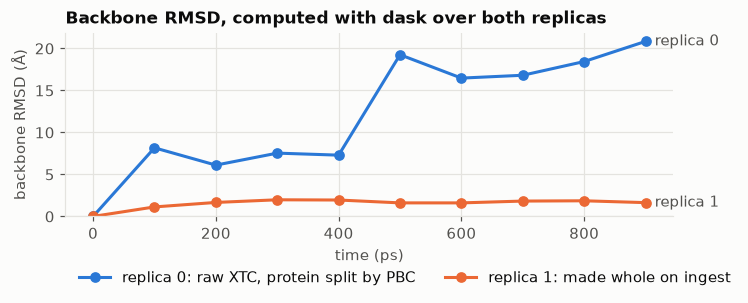

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
for rep in ds.replica.values:
    t = ds.time.sel(replica=rep).values
    y = rmsd.sel(replica=rep).values
    label = {0: "replica 0: raw XTC, protein split by PBC", 1: "replica 1: made whole on ingest"}[int(rep)]
    ax.plot(t, y, color=REPLICA_COLOR[int(rep)], marker="o", label=label)
    ax.annotate(f"replica {rep}", (t[-1], y[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK_2)
ax.set_xlabel("time (ps)")
ax.set_ylabel("backbone RMSD (Å)")
ax.set_title("Backbone RMSD, computed with dask over both replicas")
ax.set_ylim(bottom=0)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.22), ncol=2)
plt.tight_layout()
plt.show()

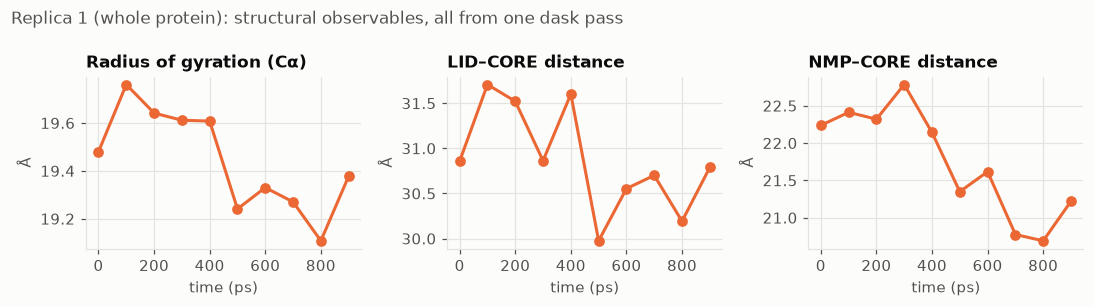

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharex=True)
t = ds.time.sel(replica=1).values
for ax, series, title in ((axes[0], rg, "Radius of gyration (Cα)"),
                          (axes[1], lid_core, "LID–CORE distance"),
                          (axes[2], nmp_core, "NMP–CORE distance")):
    ax.plot(t, series.sel(replica=1).values, color=ORANGE, marker="o")
    ax.set_title(title)
    ax.set_xlabel("time (ps)")
    ax.set_ylabel("Å")
fig.suptitle("Replica 1 (whole protein): structural observables, all from one dask pass",
             x=0.01, ha="left", fontsize=11, color=INK_2)
plt.tight_layout()
plt.show()

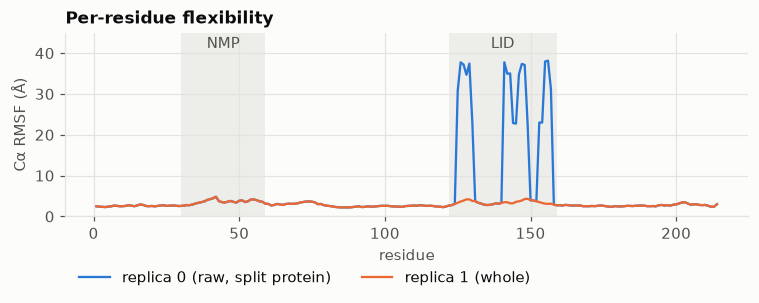

In [9]:
resid = ca.atom_resid.values
fig, ax = plt.subplots(figsize=(7, 3))
for rep in ds.replica.values:
    ax.plot(resid, rmsf.sel(replica=rep).values, color=REPLICA_COLOR[int(rep)], linewidth=1.5,
            label=f"replica {rep}" + (" (raw, split protein)" if rep == 0 else " (whole)"))
for start, end, name in ((30, 59, "NMP"), (122, 159, "LID")):
    ax.axvspan(start, end, color=GRID, alpha=0.6, linewidth=0)
    ax.text((start + end) / 2, 0.98, name, transform=ax.get_xaxis_transform(), ha="center",
            va="top", color=INK_2)
ax.set_xlabel("residue")
ax.set_ylabel("Cα RMSF (Å)")
ax.set_title("Per-residue flexibility")
ax.set_ylim(0, float(rmsf.max()) * 1.18)  # headroom so domain labels sit above the data
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.22), ncol=2)
plt.tight_layout()
plt.show()

## 5. Version everything

Each write is an Icechunk commit. A tag pins a snapshot, so an analysis can cite
exactly what it read. Any tag, branch or snapshot id can be read later.

In [10]:
lake.tag("paper-v1")
lake.add_replica("adk_water", mda.Universe(TPR, XTC), frames=slice(0, 4), metadata={"run": "run2-short"})
print("replicas now:            ", lake.system("adk_water").replicas())
print("replicas at tag paper-v1:", lake.system("adk_water", ref="paper-v1").replicas())
display(lake.history()[["snapshot", "written_at", "message"]].head(5))

replicas now:             [0, 1, 2]
replicas at tag paper-v1: [0, 1]


,snapshot,written_at,message
0,YSERTWXC3M7G4RSJRV00,2026-10-15 03:04:13.572928+00:00,add replica to adk_water
1,NNY1M308487767WZDDYG,2026-10-15 03:04:10.977452+00:00,add replica to adk_water
2,3HBR3TXAZMZSZ84NE2TG,2026-10-15 03:04:09.418289+00:00,register 1 XTC file(s) in adk_water (virtual)
3,Y1MSKKRD9TFS3AGDSADG,2026-10-15 03:04:09.403258+00:00,create system adk_water
4,2CS4PFMY5TC84CVE69Y0,2026-10-15 03:04:08.851905+00:00,create lake


## 6. Trust but verify: in-place files are watched

Each reference records the source file's mtime (or ETag on object storage). If
someone touches or rewrites the original, `verify()` reports it and Icechunk refuses
to read stale bytes.

In [11]:
later = os.path.getmtime(xtc_path) + 60
os.utime(xtc_path, (later, later))  # someone touches the original
display(lake.verify())
try:
    lake.universe("adk_water", 0)
except Exception as exc:
    print("reading it now fails loudly:", str(exc).splitlines()[0])

,system,replica,uri,status
0,adk_water,0,file:///tmp/simlake-showcase-9icups76/raw/adk_...,changed


reading it now fails loudly: the checksum of the object owning the virtual chunk has changed (file:///tmp/simlake-showcase-9icups76/raw/adk_water_run0.xtc)


## 7. The same lake on S3

The lake goes in one bucket and the raw XTC stays in place in another; references
work across buckets. Endpoints and credentials come from `sl.configure()` or the
environment, never from URIs. A local moto server stands in for AWS here.

In [12]:
from moto.server import ThreadedMotoServer

with socket.socket() as s:
    s.bind(("127.0.0.1", 0))
    port = s.getsockname()[1]
server = ThreadedMotoServer(ip_address="127.0.0.1", port=port, verbose=False)
server.start()

sl.configure("s3://", endpoint_url=f"http://127.0.0.1:{port}", allow_http=True,
             region="us-west-2", access_key_id="demo", secret_access_key="demo")
fs = sl.locations.filesystem("s3://")
fs.mkdir("md-lake")
fs.mkdir("md-raw")
fs.put(XTC, "md-raw/adk/run0.xtc")

cloud = sl.Lake.create("s3://md-lake/adk")
cloud.create_system("adk_water", TPR)
cloud.register("adk_water", "s3://md-raw/adk/run0.xtc")  # in place, in another bucket
cloud.add_replica("adk_water", run1)                     # copied in, whole
print(f"objects in s3://md-lake/adk: {len(fs.find('md-lake/adk'))}")

uri = cloud.uri("adk_water", 0)
print(f"mda.Universe({uri!r})\n  -> {mda.Universe(uri)}")

t0 = time.perf_counter()
with dask.config.set(scheduler="threads"):
    cloud_rmsd = sl.Lake.open("s3://md-lake/adk").open_dataset("adk_water").md.select("backbone").md.rmsd().compute()
print(f"dask RMSD over both cloud replicas: {time.perf_counter() - t0:.2f} s; "
      f"identical to the local lake: {np.allclose(cloud_rmsd, rmsd.sel(replica=[0, 1]), atol=1e-5)}")

objects in s3://md-lake/adk: 62
mda.Universe('simlake://s3://md-lake/adk?system=adk_water&replica=0')
  -> <Universe with 47681 atoms>


dask RMSD over both cloud replicas: 0.40 s; identical to the local lake: True


In [13]:
server.stop()
shutil.rmtree(workdir, ignore_errors=True)